<a href="https://colab.research.google.com/github/billyccw/ARIN5101-Project/blob/main/ARIN5101_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Team Information**
Group: 2

Member 1: Chan Chi Wai

Member 2:

Member 3:

In [43]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
import numpy as np
import matplotlib.pyplot as plt
import random
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
from google.colab import drive
import os
import time
from torchvision import datasets, transforms
from collections import Counter, defaultdict
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score

# set data sharepoint
drive.mount('/content/drive')
os.makedirs('/content/drive/MyDrive/ARIN5101/', exist_ok=True)

# seed setting for reproducibility
seed = 42
random.seed(seed)
rng = np.random.default_rng(seed)
torch.manual_seed(seed)
np.random.seed(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# GPU setting
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cpu


In [26]:
'''
Helper functions
'''

# this function is referenced to: https://discuss.pytorch.org/t/how-to-do-a-stratified-split/62290/5
# It is to do stratied spliting to turn training data into training set and validation set with fixed ratio of class
def stratified_split(train_data, val_size, random_seed):
  labels = np.asarray(train_data.targets)
  train_idx, validation_idx = train_test_split(np.arange(len(train_data)),
                                                test_size=val_size,
                                                random_state=random_seed,
                                                shuffle=True,
                                                stratify=labels)
  # Subset dataset for train and val
  train_dataset = Subset(train_data, train_idx)
  validation_dataset = Subset(train_data, validation_idx)
  return train_dataset, validation_dataset

# this function trains and returns a model, it also saves the resulting training/validation loss and accuracy in csv file
# name param is to set name of resulting csv file.
def train(model, loss_fn, optimizer, train_loader, val_loader, name, epochs=20):
  model_loss = {"train": [], "val": []} # each list store loss of each epoch in training and validation respectively
  model_acc = {"train": [], "val": []}
  for epoch in range(epochs):
      train_loss, train_correct, train_total, val_loss, val_correct, val_total = 0, 0, 0, 0, 0, 0
      model.train()
      for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        p = model(X_batch)
        loss = loss_fn(p, y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # performance calculation
        train_loss += loss.item() * y_batch.shape[0]
        y_hat = p.argmax(1)
        train_correct += (y_hat == y_batch).sum().item()
        train_total += y_batch.shape[0]
      model_loss["train"].append(train_loss / train_total)
      model_acc["train"].append(train_correct / train_total)

      # validation
      model.eval()
      with torch.no_grad():
        for X_batch, y_batch in val_loader:
          X_batch, y_batch = X_batch.to(device), y_batch.to(device)
          p = model(X_batch)
          loss = loss_fn(p, y_batch)
          # performance calculation
          val_loss += loss.item() * y_batch.shape[0]
          y_hat = p.argmax(1)
          val_correct += (y_hat == y_batch).sum().item()
          val_total += y_batch.shape[0]
      model_loss["val"].append(val_loss / val_total)
      model_acc["val"].append(val_correct / val_total)
      print(f"Epoch {epoch+1}: Training loss = {train_loss / train_total}, accuracy = {train_correct / train_total}; Validation loss = {val_loss / val_total}, accuracy = {val_correct / val_total}")

  # write loss and acc to csv file for future visualization
  df = pd.DataFrame({"train_loss": model_loss["train"], "train_acc": model_acc["train"], "val_loss": model_loss["val"], "val_acc": model_acc["val"]})
  save_path = '/content/drive/MyDrive/ARIN5101/train_stats'
  os.makedirs(save_path, exist_ok=True)
  df.to_csv(f'{save_path}/{name}_train_stats.csv', index=False, encoding="utf-8-sig")
  print(f"Saved statistics of training to '{save_path}/{name}_train_stats.csv'")
  return model

# this function predicts on testing set for future confusion matrix construction, also saves resulting predictions and ground-truths to csv file
# name param is to set name of resulting csv file. Better use model name
def test(model, test_loader, name):
  model.eval()
  all_preds = []
  all_labels = []
  with torch.no_grad():
    for X_batch, y_batch in test_loader:
      X_batch = X_batch.to(device)
      preds = model(X_batch).argmax(dim=1).cpu().numpy()
      all_preds.extend(preds)
      all_labels.extend(y_batch.numpy())
  df_pred = pd.DataFrame({
          "prediction": all_preds,
          "actual": all_labels
  })

  save_path = '/content/drive/MyDrive/ARIN5101/predictions'
  os.makedirs(save_path, exist_ok=True)
  df_pred.to_csv(f'{save_path}/{name}_predictions.csv', index=False, encoding="utf-8-sig")
  print(f"Saved {len(df_pred)} predictions to '{save_path}/{name}_predictions.csv'")

# this function reads and returns the train stats from csv
def read_train_stats(name):
  save_path = '/content/drive/MyDrive/ARIN5101/train_stats'
  df = pd.read_csv(f'{save_path}/{name}_train_stats.csv')
  return df['train_loss'], df['train_acc'], df['val_loss'], df['val_acc']

# this function reads and returns the testing results from csv
def read_test_results(name):
  save_path = '/content/drive/MyDrive/ARIN5101/predictions'
  df = pd.read_csv(f'{save_path}/{name}_predictions.csv')
  return df["actual"], df['prediction']


# **Dataset Loading**

In [3]:
# Download the dataset, direct load existing dataset in root if have
train_data = datasets.CIFAR100(root="/content/drive/MyDrive/ARIN5101/", train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.CIFAR100(root="/content/drive/MyDrive/ARIN5101/", train=False, download=True, transform=transforms.ToTensor())
print(train_data)
print(test_data)
print(f"Shape of an image: {train_data[0][0].shape}")

Dataset CIFAR100
    Number of datapoints: 50000
    Root location: /content/drive/MyDrive/ARIN5101/
    Split: Train
    StandardTransform
Transform: ToTensor()
Dataset CIFAR100
    Number of datapoints: 10000
    Root location: /content/drive/MyDrive/ARIN5101/
    Split: Test
    StandardTransform
Transform: ToTensor()
Shape of an image: torch.Size([3, 32, 32])


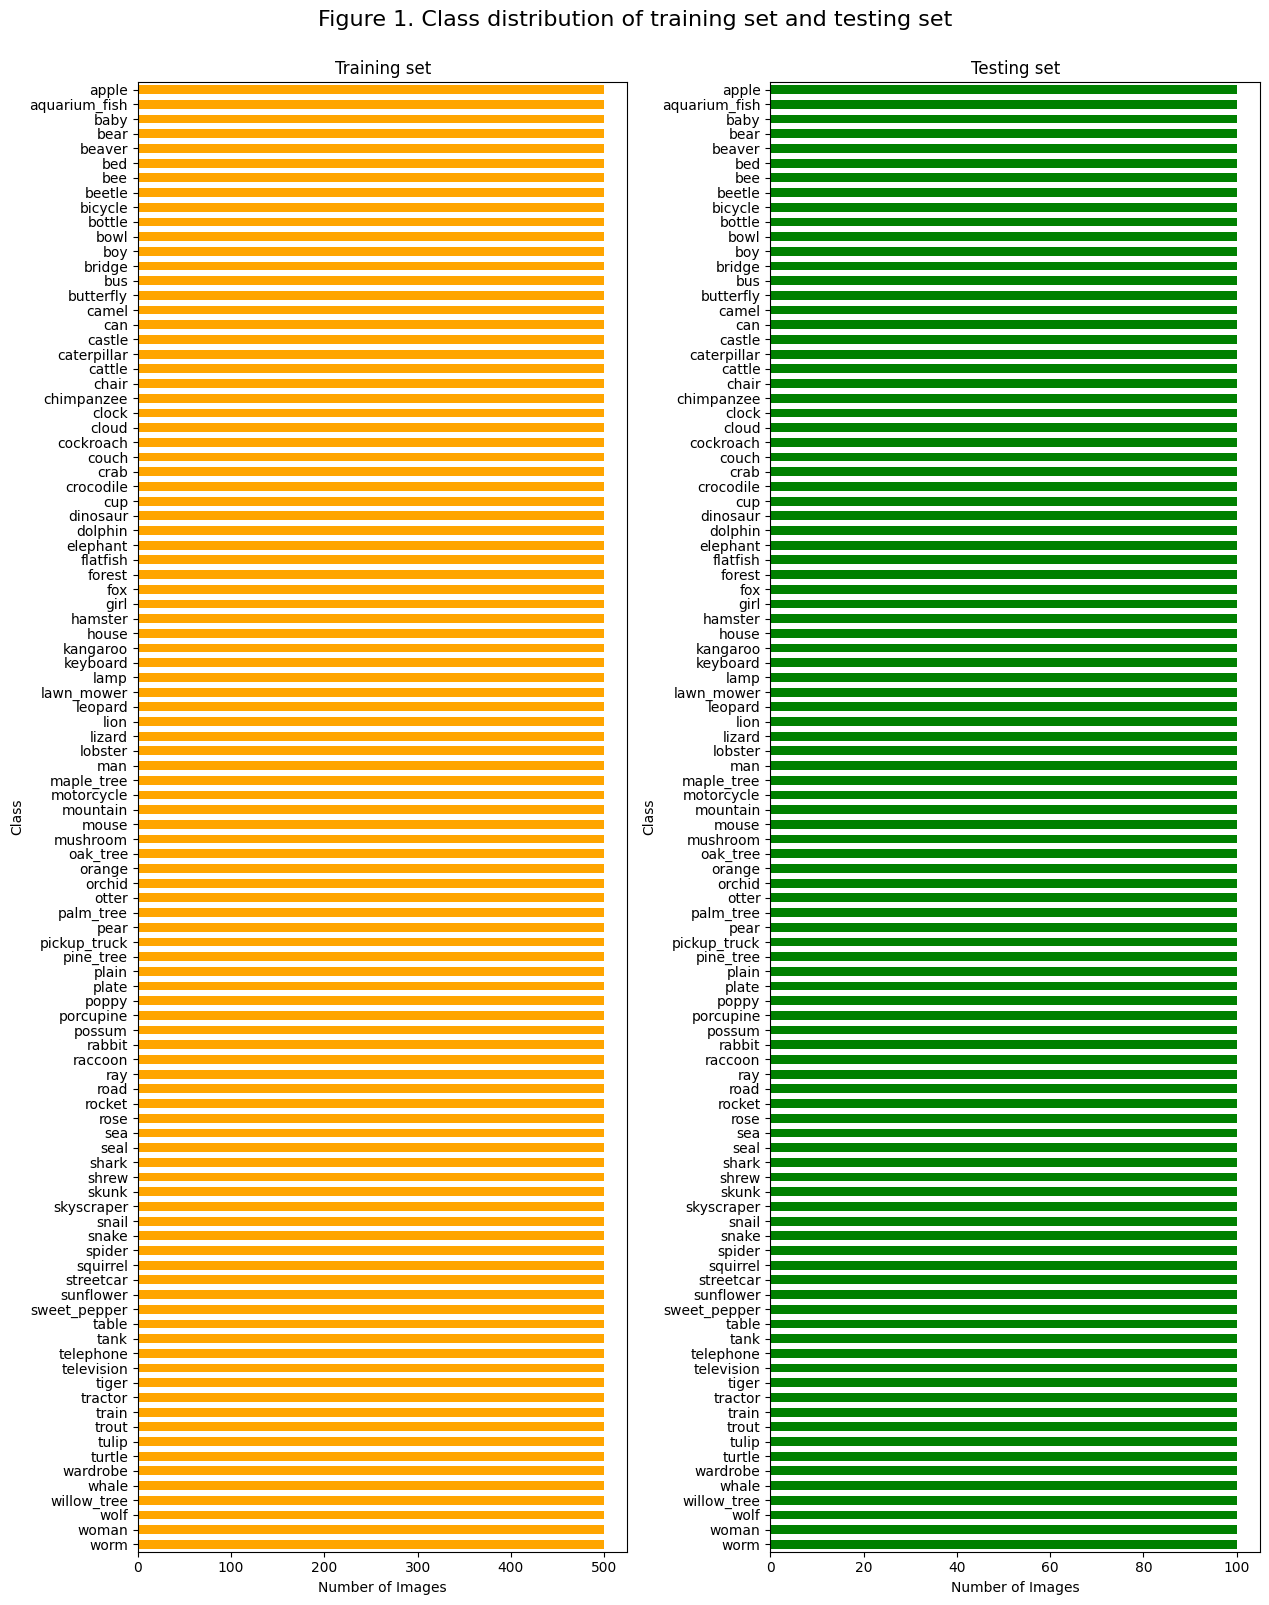

In [4]:
# visualize class distributions
y_train = [item[1] for item in train_data]
y_test = [item[1] for item in test_data]
y_train_freq = Counter(y_train)
y_test_freq = Counter(y_test)
sorted_y_train_freq = {k: v for k, v in sorted(y_train_freq.items(), key=lambda item: item[0])}
sorted_y_test_freq = {k: v for k, v in sorted(y_test_freq.items(), key=lambda item: item[0])}

plt.figure(figsize=(12.8, 16))
plt.suptitle(
    "Figure 1. Class distribution of training set and testing set",
    fontsize=16,
    y=1.,
)
plt.subplot(1, 2, 1)
plt.barh(train_data.classes, sorted_y_train_freq.values(), height=0.6, color="orange")
plt.ylim(-0.5, len(train_data.classes) - 0.5)
plt.gca().invert_yaxis()
plt.title("Training set")
plt.ylabel("Class")
plt.xlabel("Number of Images")
plt.subplot(1, 2, 2)
plt.barh(test_data.classes, sorted_y_test_freq.values(), height=0.6, color="green")
plt.ylim(-0.5, len(test_data.classes) - 0.5)
plt.gca().invert_yaxis()
plt.title("Testing set")
plt.ylabel("Class")
plt.xlabel("Number of Images")
plt.tight_layout()
plt.show()

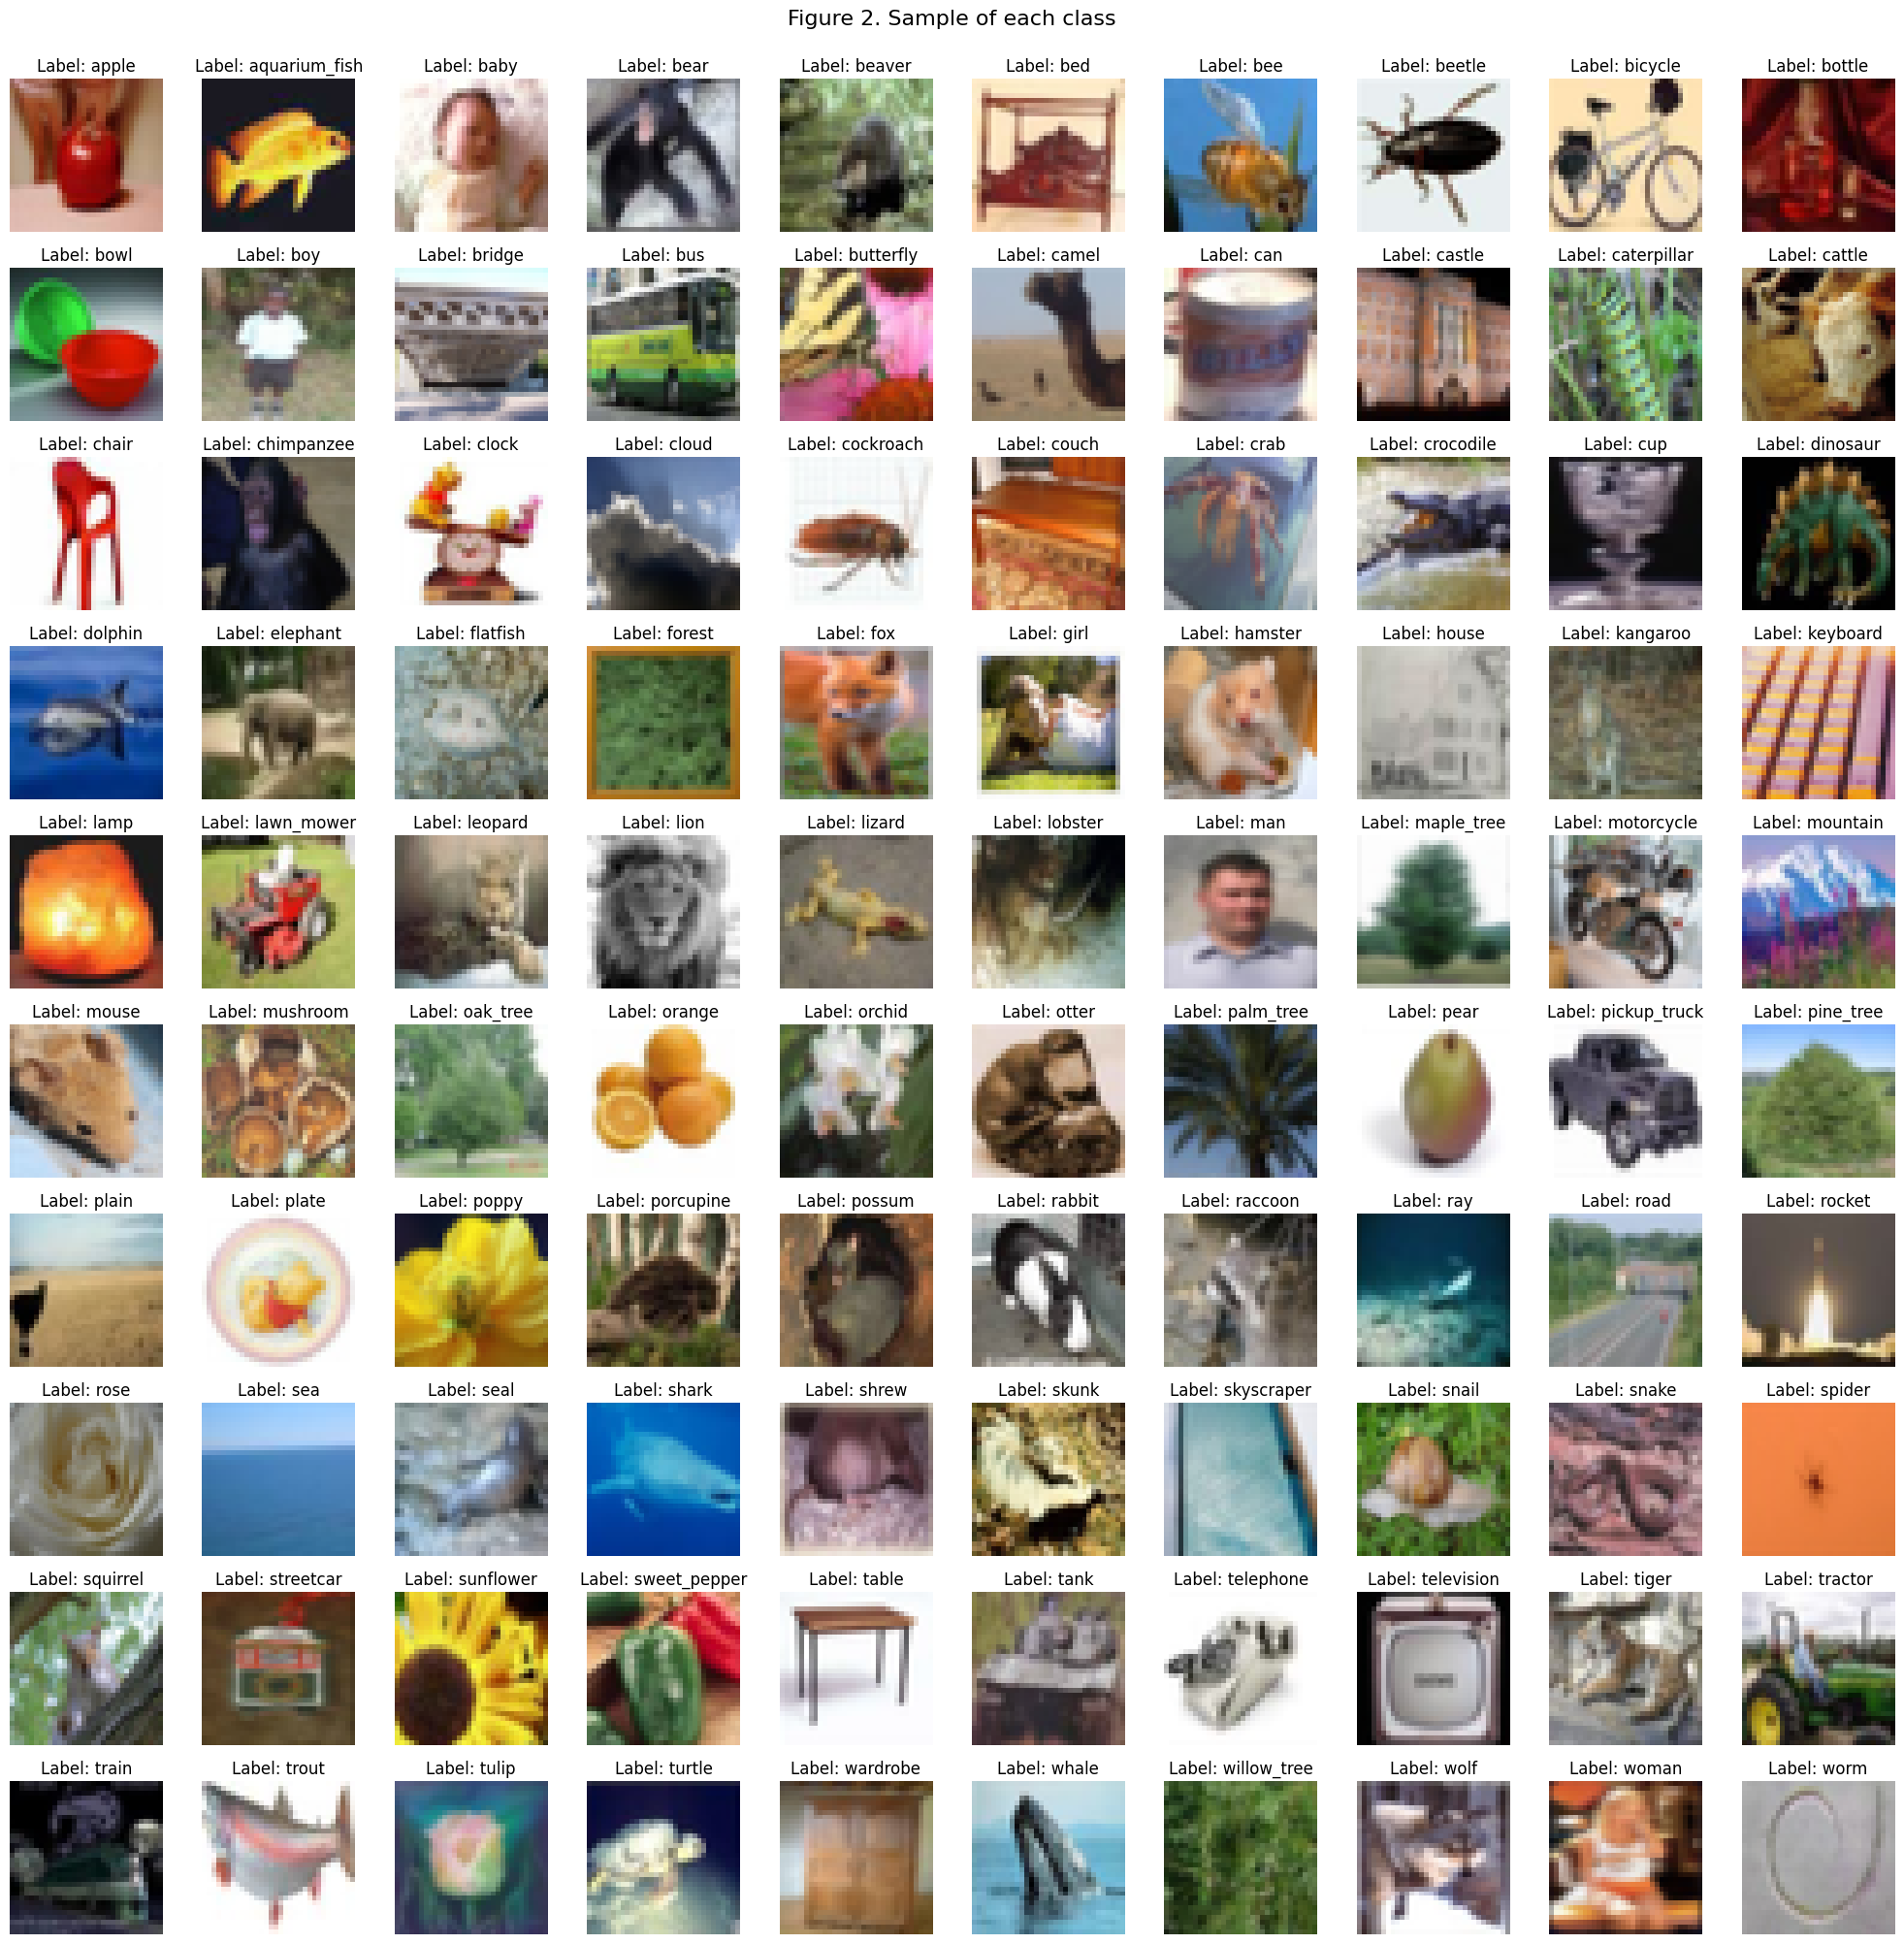

In [5]:
# sample and visualize each class
class_to_indices = {i: [] for i in range(100)}
for img_idx, label in enumerate(train_data.targets):
    class_to_indices[label].append(img_idx)

plt.figure(figsize=(20, 20))
plt.suptitle(
    "Figure 2. Sample of each class",
    fontsize=16,
    y=1.,
)
for idx, name in enumerate(train_data.classes):
  plt.subplot(10, 10, idx+1)
  available_indices = class_to_indices[idx]
  random_index = random.choice(available_indices)
  image = train_data[random_index][0]
  plt.imshow(image.numpy().transpose(1, 2, 0))
  plt.title(f"Label: {name}")
  plt.axis("off")
plt.tight_layout()
plt.show()

# Dataset Splitting and Preprocessing

In [6]:
# splitting
splitted_train_data, splitted_val_data = stratified_split(train_data, val_size=0.2, random_seed=seed)
print(len(splitted_train_data), len(splitted_val_data))

# compute mean and std for standardization
total_pixels_per_channel = len(splitted_train_data) * splitted_train_data[0][0].shape[1] * splitted_train_data[0][0].shape[2]
mean = torch.tensor([0.0, 0.0, 0.0])
std = torch.tensor([0.0, 0.0, 0.0])
for image, _ in splitted_train_data:
  for i in range(3):
    mean[i] += image[i].sum()
    std[i] += (image[i]**2).sum()

# use formula sum(x-mean)^2 = sum(x^2) - (sum(x))^2/n
for i in range(3):
  std[i] -= mean[i]**2 / total_pixels_per_channel
  std[i] /= total_pixels_per_channel
  std[i] **= 0.5
  mean[i] /= total_pixels_per_channel
print(mean, std)

transform = transforms.Compose([
  transforms.ToTensor(),
  transforms.Normalize(mean=mean.tolist(), std=std.tolist())
])

# load and split data again with the standardization preprocessing
train_data = datasets.CIFAR100(root="/content/drive/MyDrive/ARIN5101/", train=True, download=True, transform=transform)
test_data = datasets.CIFAR100(root="/content/drive/MyDrive/ARIN5101/", train=False, download=True, transform=transform)
splitted_train_data, splitted_val_data = stratified_split(train_data, val_size=0.2, random_seed=seed)

40000 10000
tensor([0.5071, 0.4863, 0.4404]) tensor([0.2673, 0.2564, 0.2761])


#### Dataset description
• Basic description, distributions and samples

As stated on the official website (https://cave.cs.toronto.edu/kriz/cifar.html), CIFAR-100 consists of 100 classes grouped into 20 superclasses. These classes cover a wide variety of objects, including animals, plants, furniture, vehicles, and natural scenes, among others. Each image is in RGB format (3 color channels) with a size of 32 x 32 pixels. The total number of images in the training and test sets is 50,000 and 10,000, respectively, where each class contributes exactly 500 training images and 100 test images. The statistics of the image distribution can be seen in Figure 1, and a sample image from each class is visualized in Figure 2.

#### Training setup and validation strategy
• Dataset splitting strategy

This project further splits the original training set into training and validation sets at a 4:1 ratio, resulting in 40,000 images in the training set and 10,000 images in the validation set. This aligns the sizes of the validation and test sets. Moreover, the partition utilizes the stratified splitting method from the scikit-learn module to ensure that every class maintains the same training-to-validation ratio.

# **Baseline CNN Architecture**

In [7]:
# Input param explaination
"""
in_channel: number of channel of input image
in_size: height/width size of input image
num_class: number of class in dataset
conv_layer_depth: Convolution layer depth -> need to be tuned
hidden_layer_size: Hidden layer size -> need to be tuned
extra_conv: bool value identifying whether a third convolutional layer should be added
"""
class baselineCNN(nn.Module):
  def __init__(self, in_channel, in_size, num_class, conv_layer_depth=32, hidden_layer_size=128, extra_conv: bool = False):
    super().__init__()
    self.extra_conv = extra_conv
    self.conv1 = nn.Conv2d(in_channels=in_channel, out_channels = conv_layer_depth, kernel_size=3, padding=1)
    self.relu1 = nn.ReLU()
    self.pool1 = nn.MaxPool2d(2)
    self.conv2 = nn.Conv2d(in_channels=conv_layer_depth, out_channels = conv_layer_depth*2, kernel_size=3, padding=1)
    self.relu2 = nn.ReLU()
    self.pool2 = nn.MaxPool2d(2)
    if extra_conv:
      self.conv3 = nn.Conv2d(in_channels=conv_layer_depth*2, out_channels = conv_layer_depth*3, kernel_size=3, padding=1)
      self.relu3 = nn.ReLU()
      self.pool3 = nn.MaxPool2d(2)
    self.flatten = nn.Flatten()
    final_img_size = in_size // (2**(2+extra_conv))
    self.linear1 = nn.Linear(final_img_size * final_img_size * conv_layer_depth*(2+extra_conv), hidden_layer_size)
    self.relu_fc = nn.ReLU()
    self.linear2 = nn.Linear(hidden_layer_size, num_class)

  def forward(self, x):
    x = self.pool1(self.relu1(self.conv1(x)))
    x = self.pool2(self.relu2(self.conv2(x)))
    if self.extra_conv:
      x = self.pool3(self.relu3(self.conv3(x)))
    x = self.flatten(x)
    x = self.relu_fc(self.linear1(x))
    x = self.linear2(x)
    return x

batch_size = 128

In [11]:
# Train and validation
start = time.time()
train_loader = DataLoader(splitted_train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(splitted_val_data, batch_size=batch_size, shuffle=False)

img_shape = train_data[0][0].shape
baseCNN_model = baselineCNN(in_channel=img_shape[0], in_size=img_shape[1], num_class=len(train_data.classes)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(baseCNN_model.parameters(), lr=0.001)

baseCNN_model = train(baseCNN_model, loss_fn, optimizer, train_loader, val_loader, "baselineCNN")

# save the model so that we do not need to train again
save_path = '/content/drive/MyDrive/ARIN5101/models'
os.makedirs(save_path, exist_ok=True)
torch.save(baseCNN_model.state_dict(), f"{save_path}/baseline_CNN.pth")

print(f"total time spent to train and save a model: {time.time()-start}s")

Epoch 1: Training loss = 3.71006268157959, accuracy = 0.14235; Validation loss = 3.193758098602295, accuracy = 0.2375
Epoch 2: Training loss = 2.9058123237609865, accuracy = 0.28425; Validation loss = 2.906405513000488, accuracy = 0.2854
Epoch 3: Training loss = 2.5386805694580077, accuracy = 0.35815; Validation loss = 2.672151850128174, accuracy = 0.3364
Epoch 4: Training loss = 2.281437524032593, accuracy = 0.4108; Validation loss = 2.564374420547485, accuracy = 0.3643
Epoch 5: Training loss = 2.0655335708618163, accuracy = 0.459875; Validation loss = 2.559584368133545, accuracy = 0.3674
Epoch 6: Training loss = 1.8870976013183594, accuracy = 0.49715; Validation loss = 2.567905638885498, accuracy = 0.369
Epoch 7: Training loss = 1.7192498558044433, accuracy = 0.539175; Validation loss = 2.561998991394043, accuracy = 0.3727
Epoch 8: Training loss = 1.5577555545806885, accuracy = 0.5758; Validation loss = 2.6241079895019532, accuracy = 0.3795
Epoch 9: Training loss = 1.4056595951080322

In [8]:
# After training, do predictions on testing set for final performance matrix calculation
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

img_shape = test_data[0][0].shape
baseCNN_model = baselineCNN(in_channel=img_shape[0], in_size=img_shape[1], num_class=len(train_data.classes)).to(device)
baseCNN_model.load_state_dict(torch.load('/content/drive/MyDrive/ARIN5101/models/baseline_CNN.pth', map_location=device))
test(baseCNN_model, test_loader, "baselineCNN")

Saved 10000 predictions to '/content/drive/MyDrive/ARIN5101/predictions/baselineCNN_predictions.csv'


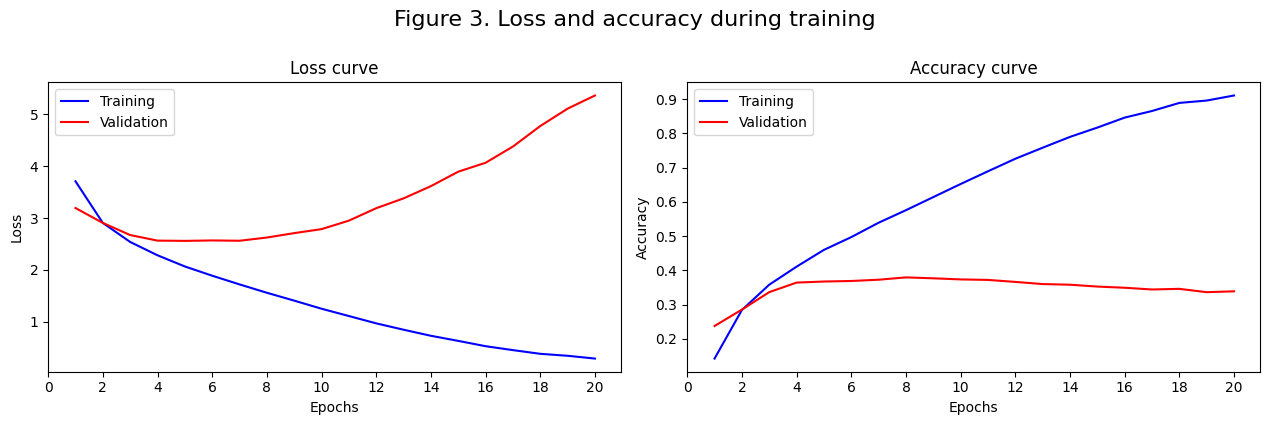

In [23]:
# Visualize training loss and accuracy
train_loss, train_acc, val_loss, val_acc = read_train_stats("baselineCNN")

plt.figure(figsize=(12.8, 4.2))
plt.suptitle(
    "Figure 3. Loss and accuracy during training",
    fontsize=16,
    y=1.,
)
plt.subplot(1, 2, 1)
plt.plot(list(range(1, 21)), train_loss, label="Training", color="blue")
plt.plot(list(range(1, 21)), val_loss, label="Validation", color="red")
plt.legend()
plt.title("Loss curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.xticks(np.linspace(0, 20, 11))

plt.subplot(1, 2, 2)
plt.plot(list(range(1, 21)), train_acc, label="Training", color="blue")
plt.plot(list(range(1, 21)), val_acc, label="Validation", color="red")
plt.legend()
plt.title("Accuracy curve")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.xticks(np.linspace(0, 20, 11))

plt.tight_layout()
plt.show()



In [42]:
# Computing testing performance
y_test, y_pred = read_test_results("baselineCNN")

'''
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(20, 20))
display = ConfusionMatrixDisplay(cm, display_labels=test_data.classes)
display.plot(cmap="Greens", ax=ax)
plt.show()
'''
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
print(f"Performance in testing set:")
print(f"Accuracy: {'{:.4f}'.format(accuracy)}\nPrecision: {'{:.4f}'.format(precision)}\nRecall: {'{:.4f}'.format(recall)}")


Performance in testing set:
Accuracy: 0.3316
Precision: 0.3506
Recall: 0.3316


#### Basic illustration
The default baseline CNN consists of two convolutional blocks followed by a fully connected classifier. Each convolutional block contains a Conv2d layer with kernel size = 3 and padding = 1, which keeps the spatial dimensions (H, W) unchanged within each convolution, followed by ReLU activation and a max pooling that halves the spatial dimensions.

The output channels of the first and second convolutional layers are 32 and 64 respectively in the default setting

After the convolutional blocks, the feature map is flattened into a 1D vector and passed to a fully connected classifier with one hidden layer of 128 units followed by ReLU. The output layer has num_class units producing raw logits; no softmax is applied explicitly because nn.CrossEntropyLoss incorporates it internally.

Note that the baseline cnn is trained with 20 epochs, with batch size of 128 and learning rate of 0.001.

#### Performance Analyse
• loss, accuracy, confusion matrix and other relevant metrics

As shown in Figure 3, the training loss and accuracy improve at a slightly decreasing rate, indicating steady convergence on the training set. However, the validation loss and accuracy worsen at an early stage, starting from epoch 3. This indicates significant overfitting in the baseline CNN model. Such a result is foreseeable, given that there are 100 classes in total, but each class contains only 400 images as training data after partitioning 100 images for the validation set. It is challenging for a baseline CNN model to learn generalized features from such a limited training dataset.

Considering the inefficiency of visualizing a confusion matrix with a large number of classes (100), we decided to compute weighted scores to assess the performance on the test set. The low accuracy of 0.3316 is consistent with the validation accuracy at the final epoch, while a slightly higher precision (0.3506) compared to the recall (0.3316) suggests that the model is more prone to producing False Negatives than False Positives.


# **Tuning hyperparam in baseline**

In [ ]:
# Not Implemented Yet

#### Basic illustration

#### Performance Analyse
• Comparisons among the combinations using relevant metrics

# **CNN model with improvement A**

In [ ]:
# Not Implemented Yet

#### Basic illustration

#### Performance Analyse
• Comparisons among the combinations using relevant metrics

# **CNN model with improvement B**

In [ ]:
# Not Implemented Yet

#### Basic illustration

#### Performance Analyse
• Comparisons among the combinations using relevant metrics

# **CNN model with improvements A and B**

In [ ]:
# Not Implemented Yet

#### Basic illustration

#### Performance Analyse
• Comparisons among the combinations using relevant metrics

# **Final model summary and reflections**

In [ ]:
# visualize performance of all models

• Which one is the best performing model and why

• Higher accuracy does not necessarily indicate a better model